# Snow-related mass variations in the Alps from GRACE/GRACE-FO

Step-by-step version of `run_analysis.py`. Data: GravIS GFZ RL06 and COST-G RL02 Level-3 TWS (GFZ),
ERA5-Land monthly SWE and soil moisture (Copernicus C3S).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "dpi": 80}

from src.grace import load_tws, regional_mean, to_series, ZUGSPITZE
from src.era5 import load_era5, glacier_mask, to_grace_grid
from src.timeseries import fit_seasonal_trend, monthly_climatology, to_monthly, anomaly, missing_months
from src.smoothing import smooth

## 1. GRACE TWS (GravIS)
1° grid, land only, anomalies in cm relative to 2002-04 – 2020-03 (converted to mm here).

In [2]:
gfz = load_tws("GFZ RL06")
costg = load_tws("COST-G RL02")
gfz

<xarray.Dataset> Size: 10MB
Dimensions:           (time: 260, lat: 28, lon: 44)
Coordinates:
  * time              (time) datetime64[ns] 2kB 2002-04-18T06:59:59 ... 2026-...
  * lat               (lat) float32 112B 34.5 35.5 36.5 37.5 ... 59.5 60.5 61.5
  * lon               (lon) float32 176B -11.5 -10.5 -9.5 ... 29.5 30.5 31.5
Data variables:
    tws               (time, lat, lon) float64 3MB nan nan nan ... -144.2 -158.1
    std_tws           (time, lat, lon) float64 3MB nan nan nan ... 22.72 22.72
    leakage           (time, lat, lon) float64 3MB nan nan nan ... 188.8 198.6
    model_atmosphere  (time, lat, lon) float64 3MB nan nan nan ... -19.18 -19.04
Attributes: (12/15)
    Conventions:          CF-1.6
    title:                Globally Gridded Continental Water Storage Anomalies
    doi:                  10.5880/GFZ.GRAVIS_06_L3_TWS
    institution:          GFZ Section 1.3: Earth System Modelling
    authors:              Eva Boergens, Henryk Dobslaw, Robert Dill
    contact:              boergens@gfz-potsdam.de
    ...                   ...
    time_coverage_start:  2002-04
    time_coverage_end:    2026-08
    product_release:      06
    product_version:      0006
    date_created:         2026-09-29
    subset_note:          Subset to 12W-32E, 34N-62N by grace-snow-alps proje...

In [3]:
s = to_series(gfz.tws.sel(lat=47.5, lon=10.5))
print("months:", len(s), "| first:", s.index[0].date(), "| last:", s.index[-1].date())
print("missing calendar months:", len(missing_months(s)))
print(missing_months(s))

months: 260 | first: 2002-04-18 | last: 2026-08-16
missing calendar months: 35
['2002-06', '2002-07', '2003-06', '2011-01', '2011-06', '2011-11', '2012-05', '2012-10', '2013-03', '2013-08', '2013-09', '2014-02', '2014-07', '2014-12', '2015-05', '2015-06', '2015-10', '2015-11', '2016-04', '2016-09', '2016-10', '2017-02', '2017-07', '2017-08', '2017-09', '2017-10', '2017-11', '2017-12', '2018-01', '2018-02', '2018-03', '2018-04', '2018-05', '2018-08', '2018-09']


## 2. ERA5-Land SWE and soil moisture
Glacier points are fixed at about 10 m w.e. in ERA5-Land and are removed.

glacier points: 30


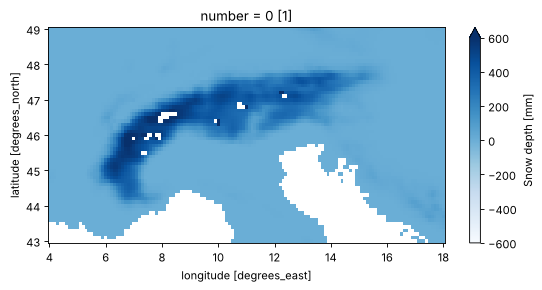

In [4]:
era = load_era5()
glac = glacier_mask(era.swe)
print("glacier points:", int(glac.sum()))
swe = era.swe.where(~glac)
soil = era.soil.where(~glac)
swe.where(swe.time.dt.month == 3, drop=True).mean("time").plot(cmap="Blues", vmax=600, figsize=(8, 3.5));

## 3. ERA5-Land on the 1° GRACE grid and the study region

cells in region: 21


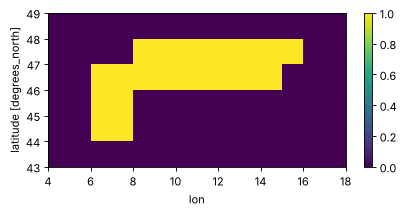

In [5]:
swe_1deg = to_grace_grid(swe, gfz.lat, gfz.lon)
soil_1deg = to_grace_grid(soil, gfz.lat, gfz.lon)

yearly_max = swe_1deg.groupby("time.year").max("time")
mean_max = yearly_max.where(yearly_max.year < 2026).mean("year")
in_box = (gfz.lon >= 5) & (gfz.lon <= 16.5) & (gfz.lat >= 43.5) & (gfz.lat <= 48.5)
ok = gfz.tws.notnull().all("time") & costg.tws.notnull().all("time")
region = (in_box & ok & (mean_max >= 50)).fillna(False).transpose("lat", "lon")
print("cells in region:", int(region.sum()))
region.sel(lat=slice(43, 49), lon=slice(4, 18)).plot(figsize=(6, 2.5));

## 4. Regional series

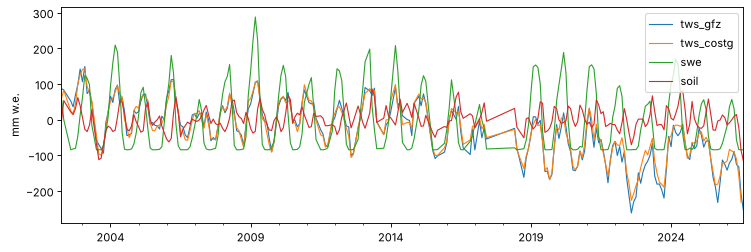

In [6]:
REF = ("2002-04", "2020-03")
ms = lambda da: to_monthly(to_series(da))
tws = ms(regional_mean(gfz.tws, region))
tws_c = ms(regional_mean(costg.tws, region))
swe_r = anomaly(ms(regional_mean(swe_1deg, region)), *REF)
soil_r = anomaly(ms(regional_mean(soil_1deg, region)), *REF)

df = pd.DataFrame({"tws_gfz": tws, "tws_costg": tws_c, "swe": swe_r, "soil": soil_r}).loc[tws.index]
df.plot(figsize=(11, 3.5), lw=1); plt.ylabel("mm w.e.");

## 5. Seasonal and trend fit
`y = a + b t + annual + semi-annual` by least squares.

In [7]:
def fit(s):
    s2 = s.dropna().copy(); s2.index = s2.index.to_timestamp() + pd.Timedelta(days=14)
    r = fit_seasonal_trend(s2)
    return {k: round(float(v), 1) for k, v in r.items() if not isinstance(v, pd.Series)}

pd.DataFrame({k: fit(df[k]) for k in df.columns}).T

,n,offset,trend_per_yr,trend_err,lag1_autocorr,n_eff,trend_err_ar1,annual_amp,annual_amp_err,annual_max_doy,semiannual_amp,residual_std
tws_gfz,258.0,1.6,-7.7,0.4,0.7,43.1,0.9,57.8,3.6,73.8,8.7,41.3
tws_costg,257.0,1.3,-6.8,0.3,0.8,28.3,1.1,60.2,3.3,70.2,8.1,37.0
swe,258.0,-2.3,-0.8,0.3,0.8,31.3,1.0,107.7,3.4,63.2,30.2,38.1
soil,258.0,-0.5,0.2,0.2,0.6,57.4,0.5,12.8,2.2,143.2,27.3,24.7


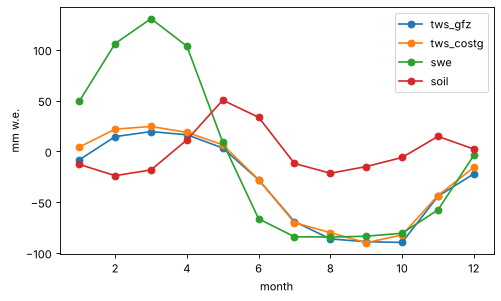

In [8]:
clim = pd.DataFrame({k: monthly_climatology(df[k].set_axis(df.index.to_timestamp())) for k in df.columns})
clim.plot(marker="o", figsize=(7, 4)); plt.xlabel("month"); plt.ylabel("mm w.e.");

## 6. What would SWE look like at GRACE resolution?
Gaussian smoothing on the sphere (300 km) as a simple stand-in for GRACE filtering.

In [9]:
swe_s = smooth(swe_1deg.rename("swe"), 300)
swe_s_r = anomaly(ms(regional_mean(swe_s, region)), *REF).loc[tws.index]
print("annual amplitude  TWS:", fit(df.tws_gfz)["annual_amp"],
      "| SWE:", fit(df.swe)["annual_amp"], "| SWE smoothed:", fit(swe_s_r)["annual_amp"])

annual amplitude  TWS: 57.8 | SWE: 107.7 | SWE smoothed: 29.2


## 7. Zugspitze: point vs. 1° cell vs. GRACE

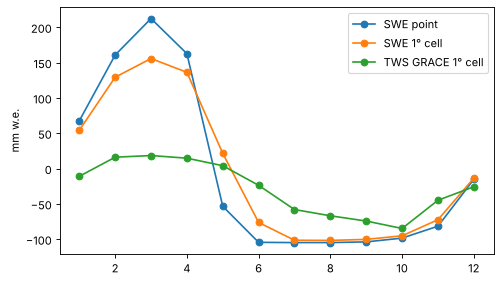

In [10]:
pt = swe.sel(lat=47.4, lon=11.0, method="nearest")      # nearest non-glacier ERA5-Land point
z = pd.DataFrame({
    "SWE point": anomaly(ms(pt), *REF),
    "SWE 1° cell": anomaly(ms(swe_1deg.sel(lat=47.5, lon=10.5)), *REF),
    "TWS GRACE 1° cell": ms(gfz.tws.sel(lat=47.5, lon=10.5)),
}).loc[tws.index]
zc = pd.DataFrame({k: monthly_climatology(z[k].set_axis(z.index.to_timestamp())) for k in z.columns})
zc.plot(marker="o", figsize=(7, 4)); plt.ylabel("mm w.e.");

## 8. Summary

- GRACE TWS in the Alpine snow region peaks in March and is lowest in August–October, like SWE.
- ERA5-Land SWE has a larger annual amplitude than GRACE TWS; smoothed SWE has a smaller one.
  Filtering/leakage, model biases and runoff all play a role.
- Regional TWS declines by about 7 mm/yr, mostly after 2018, without a matching trend in SWE or soil moisture.
- At Zugspitze the local snow signal is much larger than what GRACE shows for the same 1° cell.